# EDA of the El Nino Dataset

In [37]:
## Setup of the environment and fetching the data from link

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt"
oni = pd.read_csv(url, sep=r"\s+")

seasons = ['DJF', 'JFM', 'FMA', 'MAM', 'AMJ', 'MJJ', 'JJA', 'JAS', 'ASO', 'SON', 'OND', 'NDJ']
end_month = {s: (i + 1) % 12 + 1 for i, s in enumerate(seasons)}

oni["month"] = oni["SEAS"].map(end_month)
# YR is the year of the middle month, so NDJ (ends in January) belongs to next year
oni["year"] = oni["YR"] + (oni["SEAS"] == "NDJ")
oni["date"] = pd.to_datetime(dict(year=oni["year"], month=oni["month"], day=1))
oni = oni.set_index("date").drop(columns=["month", "year"])

oni.tail()

,SEAS,YR,TOTAL,ANOM
date,,,,
2026-05-01,MAM,2026,28.09,0.46
2026-06-01,AMJ,2026,28.74,0.95
2026-07-01,MJJ,2026,29.02,1.39
2026-08-01,JJA,2026,29.09,1.80
2026-09-01,JAS,2026,29.12,2.16


In [38]:
# Final two checks
oni.index.is_monotonic_increasing, oni.index.is_unique, oni.isna().sum().sum()

(True, True, np.int64(0))

In [39]:
# No gaps in time axis
full = pd.date_range(oni.index.min(), oni.index.max(), freq="MS")
len(full) == len(oni), full.difference(oni.index)

(True, DatetimeIndex([], dtype='datetime64[us]', freq='MS'))

In [40]:
# Season label matches index month
assert (oni["SEAS"].str[-1] == oni.index.strftime("%b").str[0].str.upper()).all()

In [41]:
# Known events 
display(oni["ANOM"].loc["1997":"1998"].idxmax()) # El Nino
display(oni["ANOM"].loc["2015":"2016"].idxmax()) # El Nino
display(oni["ANOM"].loc["2010":"2011"].idxmin()) # El Nina

Timestamp('1998-01-01 00:00:00')

Timestamp('2016-01-01 00:00:00')

Timestamp('2010-12-01 00:00:00')

In [42]:
# Value ranges
oni.describe()

,YR,TOTAL,ANOM
count,920.000000,920.000000,920.000000
mean,1987.834783,26.936315,0.020978
std,22.144419,0.906355,0.790342
min,1950.000000,24.390000,-2.040000
25%,1969.000000,26.310000,-0.510000
50%,1988.000000,26.980000,-0.040000
75%,2007.000000,27.570000,0.500000
max,2026.000000,29.150000,2.590000


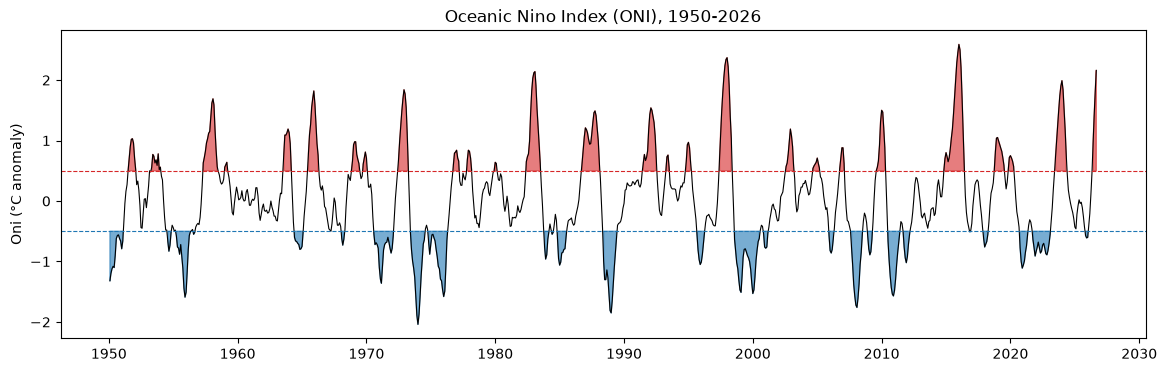

In [43]:
# Full history El Nino / La Nina
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(oni.index, oni["ANOM"], color="black", lw=0.8)
ax.fill_between(oni.index, oni["ANOM"], 0.5, where=oni["ANOM"] >= 0.5, color="tab:red", alpha=0.6)
ax.fill_between(oni.index, oni["ANOM"], -0.5, where=oni["ANOM"] <= -0.5, color="tab:blue", alpha=0.6)
ax.axhline(0.5, color="tab:red", ls="--", lw=0.8)
ax.axhline(-0.5, color="tab:blue", ls="--", lw=0.8)
ax.set(title="Oceanic Nino Index (ONI), 1950-2026", ylabel="Oni (°C anomaly)")
plt.show()

In [44]:
# Classify events
oni["PHASE"] = np.select([oni["ANOM"] >= 0.5, oni["ANOM"] <= -0.5], ["El Nino", "La Nina"], default="Neutral")
oni["PHASE"].value_counts(normalize=True)

PHASE
Neutral    0.486957
La Nina    0.258696
El Nino    0.254348
Name: proportion, dtype: float64

In [45]:
def run_flag(mask, n=5):
    run_id = (mask != mask.shift()).cumsum()
    run_length = mask.groupby(run_id).transform("size")
    return mask & (run_length >= n)

oni["EVENT"] = np.select(
    [run_flag(oni["ANOM"] >= 0.5), run_flag(oni["ANOM"] <= -0.5)],
    ["El Nino", "La Nina"], default="Neutral")

pd.crosstab(oni["PHASE"], oni["EVENT"])

EVENT,El Nino,La Nina,Neutral
PHASE,,,
El Nino,215,0,19
La Nina,0,221,17
Neutral,0,0,448


In [46]:
# Event statistics by grouping consecutive EVENT runs
oni["run"] = oni["EVENT"].ne(oni["EVENT"].shift()).cumsum()

events = (
    oni[oni["EVENT"] != "Neutral"]
    .groupby("run")
    .agg(
        type=("EVENT", "first"),
        start=("ANOM", lambda s: s.index[0]),
        end=("ANOM", lambda s: s.index[-1]),
        duration=("ANOM", "size"),
        peak=("ANOM", lambda s: s.loc[s.abs().idxmax()]),
        peak_date=("ANOM", lambda s: s.abs().idxmax()),
        mean_anom=("ANOM", "mean"),
    )
    .reset_index(drop=True)
)
oni = oni.drop(columns="run")
events.sort_values("peak", key=abs, ascending=False).head(10)

,type,start,end,duration,peak,peak_date,mean_anom
35,El Nino,2014-11-01,2016-06-01,20,2.59,2016-01-01,1.389500
23,El Nino,1997-06-01,1998-05-01,12,2.37,1998-01-01,1.721667
15,El Nino,1982-06-01,1983-07-01,14,2.14,1983-02-01,1.352857
11,La Nina,1973-06-01,1974-07-01,14,-2.04,1974-01-01,-1.230000
41,El Nino,2023-07-01,2024-05-01,11,1.99,2024-01-01,1.402727
19,La Nina,1988-06-01,1989-06-01,13,-1.85,1989-01-01,-1.290000
10,El Nino,1972-07-01,1973-04-01,10,1.84,1972-12-01,1.299000
7,El Nino,1965-07-01,1966-04-01,10,1.82,1965-12-01,1.278000
30,La Nina,2007-09-01,2008-07-01,11,-1.76,2008-02-01,-1.244545
4,El Nino,1957-05-01,1958-06-01,14,1.69,1958-02-01,1.092857


In [47]:
events["type"].value_counts()
events.groupby("type")[["duration", "peak"]].describe().round(2)

duration                                             peak              \
           count   mean   std  min   25%   50%    75%   max count  mean   std   
type                                                                            
El Nino     22.0   9.77  3.95  5.0  7.25   9.0  11.75  20.0  22.0  1.37  0.56   
La Nina     20.0  11.05  5.46  5.0  6.50  10.0  14.00  24.0  20.0 -1.24  0.39   

                                       
          min   25%   50%   75%   max  
type                                   
El Nino  0.71  0.90  1.19  1.79  2.59  
La Nina -2.04 -1.57 -1.08 -0.90 -0.76

In [48]:
oni.to_csv("data/oni.csv")
events.to_csv("data/events.csv", index=False)